# ***Checking Inputs***

In [1]:
import os

os.listdir("/kaggle/input")

['amazon-cells-labelled-txt']

# ***Dataset***

In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/amazon-cells-labelled-txt/Amazon.csv")

df.head()

,Sentence,Label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


# ***Task 1: Text Preprocessing***

In [3]:
import string
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [4]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Lowercase
    text = text.lower()
    
    # Punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # Numbers
    text = re.sub(r'\d+', '', text)
    
    # Tokenize
    tokens = text.split()
    
    # Stopwords & Lemmatize
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    
    return " ".join(tokens)

df["Cleaned_Sentence"] = df["Sentence"].apply(preprocess_text)
df[["Sentence", "Cleaned_Sentence"]].head()

,Sentence,Cleaned_Sentence
0,So there is no way for me to plug it in here i...,way plug u unless go converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great jawbone
3,Tied to charger for conversations lasting more...,tied charger conversation lasting minutesmajor...
4,The mic is great.,mic great


# ***Top 20 Most Frequent Words***

In [5]:
from collections import Counter
import matplotlib.pyplot as plt

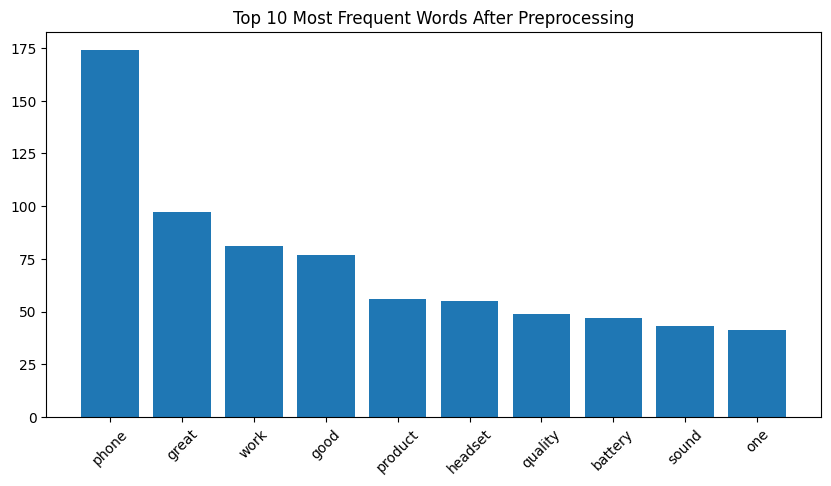

In [6]:
all_words = " ".join(df["Cleaned_Sentence"]).split()
word_freq = Counter(all_words)

common_words = word_freq.most_common(10)
words, counts = zip(*common_words)

plt.figure(figsize=(10,5))
plt.bar(words, counts)
plt.xticks(rotation=45)
plt.title("Top 10 Most Frequent Words After Preprocessing")
plt.show()

# ***Sentence Length Comparison***

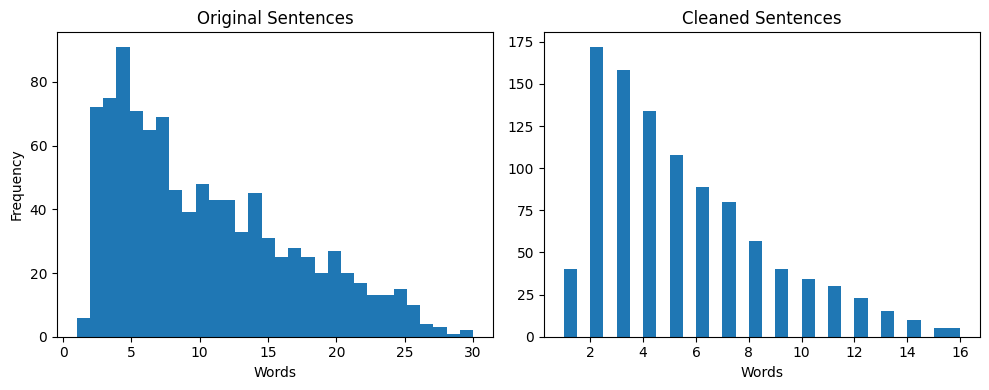

In [7]:
plt.figure(figsize=(10,4))

plt.subplot(1, 2, 1)
plt.hist(df["Sentence"].str.split().str.len(), bins=30)
plt.title("Original Sentences")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(df["Cleaned_Sentence"].str.split().str.len(), bins=30)
plt.title("Cleaned Sentences")
plt.xlabel("Words")

plt.tight_layout()
plt.show()

# ***Word Cloud***

In [8]:
from wordcloud import WordCloud

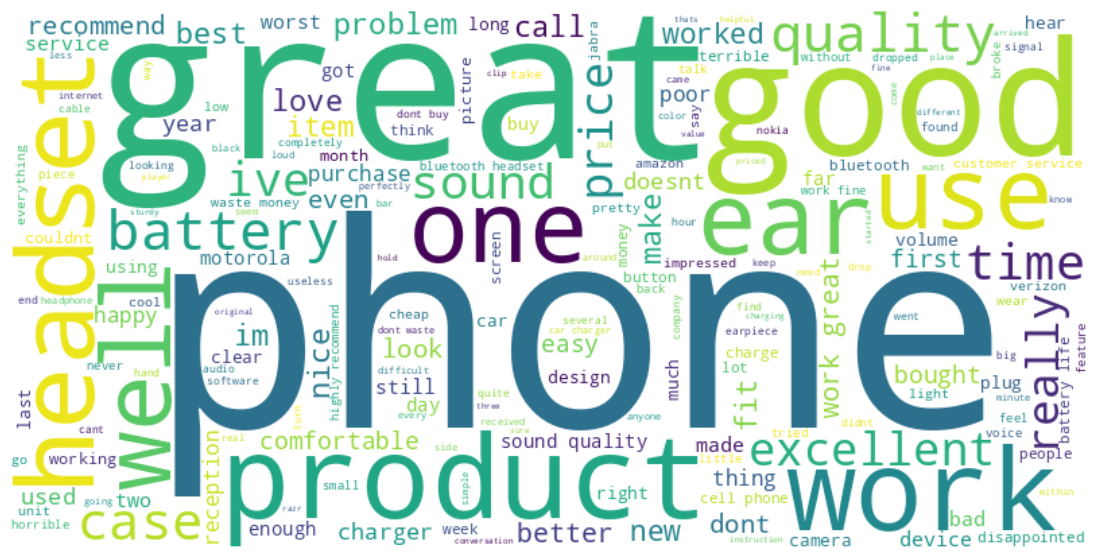

In [9]:
text = " ".join(df["Cleaned_Sentence"])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

## ***Analysis of Preprocessing Results***

The text was cleaned using **lowercasing, punctuation removal, number removal, stop word removal, and lemmatization**.

## ***Effect of Preprocessing***
- Sentences became shorter and cleaner.  
  Example: `"So there is no way for me to plug it in here..." → "way plug u unless go converter"`
- Key words like `"great"`, `"mic"`, `"case"`, `"jawbone"` remain.
- Words were reduced to their base form: `"conversations" → "conversation"`.
- Numbers and filler words were removed, reducing noise.

## ***Observed Patterns***

| Cleaned Sentence | Notes |
|-----------------|-------|
| `"way plug u unless go converter"` | Negative / frustration |
| `"good case excellent value"` | Positive |
| `"great jawbone"` | Positive |
| `"tied charger conversation lasting minutesmajor..."` | Negative / inconvenience |
| `"mic great"` | Positive |

# ***Task 2: Bag of Words***

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

In [11]:
X = df["Cleaned_Sentence"]
y = df["Label"]

vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_bow, y, test_size=0.3, random_state=42, stratify=y
)

# ***Class Specific Word Importance***

In [12]:
import numpy as np

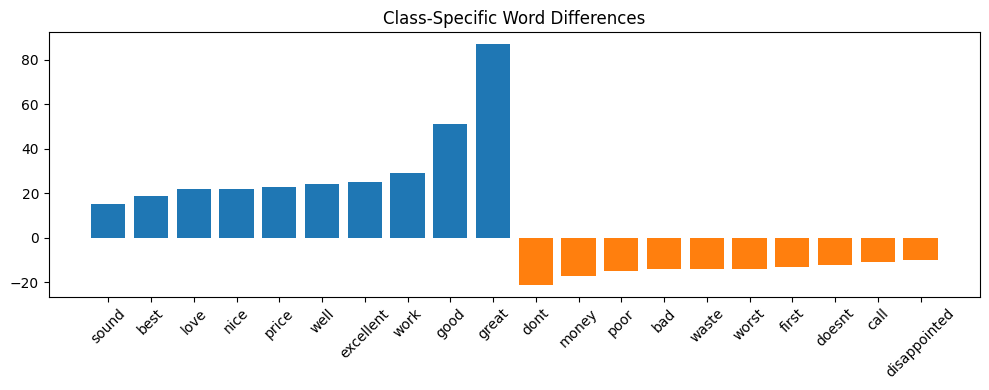

In [13]:
class_0_idx = y[y == 0].index
class_1_idx = y[y == 1].index

X_class0 = X_bow[class_0_idx]
X_class1 = X_bow[class_1_idx]

freq_0 = X_class0.sum(axis=0)
freq_1 = X_class1.sum(axis=0)

diff = freq_1 - freq_0

top_pos = np.argsort(diff.A1)[-10:]
top_neg = np.argsort(diff.A1)[:10]

feature_names = vectorizer.get_feature_names_out()

words_pos = feature_names[top_pos]
words_neg = feature_names[top_neg]

plt.figure(figsize=(10,4))
plt.bar(words_pos, diff.A1[top_pos])
plt.bar(words_neg, diff.A1[top_neg])
plt.xticks(rotation=45)
plt.title("Class-Specific Word Differences")
plt.tight_layout()
plt.show()

# ***Task 2: Classification***

In [14]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [15]:
# Naïve Bayes

nb = MultinomialNB()
nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.76
              precision    recall  f1-score   support

           0       0.80      0.70      0.74       150
           1       0.73      0.82      0.77       150

    accuracy                           0.76       300
   macro avg       0.76      0.76      0.76       300
weighted avg       0.76      0.76      0.76       300



In [16]:
# Logistic Regression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.7833333333333333
              precision    recall  f1-score   support

           0       0.76      0.83      0.79       150
           1       0.81      0.73      0.77       150

    accuracy                           0.78       300
   macro avg       0.79      0.78      0.78       300
weighted avg       0.79      0.78      0.78       300



In [17]:
# Support Vector Machine

svm = LinearSVC()
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.8066666666666666
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       150
           1       0.82      0.78      0.80       150

    accuracy                           0.81       300
   macro avg       0.81      0.81      0.81       300
weighted avg       0.81      0.81      0.81       300



# ***Classification Report***

The table below summarizes the performance of Naive Bayes, Logistic Regression, and SVM on the dataset.

| Model | Accuracy | Precision (Class 0 / 1) | Recall (Class 0 / 1) | F1-score (Class 0 / 1) |
|-------|---------|-------------------------|---------------------|------------------------|
| Naive Bayes | 0.76 | 0.80 / 0.73 | 0.70 / 0.82 | 0.74 / 0.77 |
| Logistic Regression | 0.78 | 0.76 / 0.81 | 0.83 / 0.73 | 0.79 / 0.77 |
| SVM | 0.81 | 0.79 / 0.82 | 0.83 / 0.78 | 0.81 / 0.80 |

## ***Observations***
- **SVM performed best** with 81% accuracy, followed by Logistic Regression (78%) and Naive Bayes (76%).  
- **Naive Bayes** has higher recall for class 1 but lower recall for class 0, indicating it predicts class 1 better.  
- **Logistic Regression** balances precision and recall between both classes.  
- **SVM** gives the most consistent performance across both classes.  
- Using **Bag-of-Words**, linear models (Logistic Regression, SVM) generally outperform Naive Bayes on this dataset.

# ***Confusion Matrices***

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

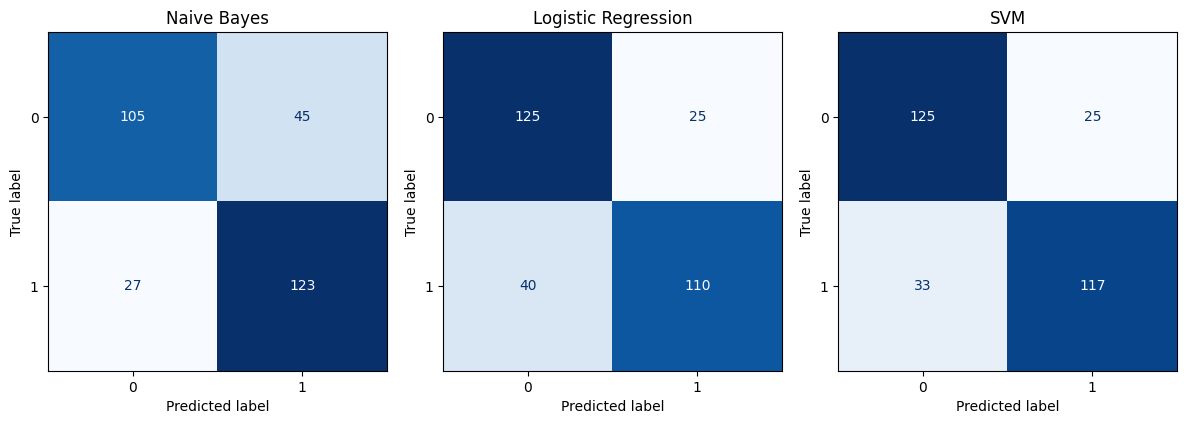

In [19]:
models = {
    "Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr,
    "SVM": y_pred_svm
}

plt.figure(figsize=(12,4))

for i, (name, y_pred) in enumerate(models.items(), 1):
    plt.subplot(1,3,i)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm)
    disp.plot(cmap="Blues", values_format="d", ax=plt.gca(), colorbar=False)
    plt.title(name)

plt.tight_layout()
plt.show()

# ***Accuracy Comparison***

In [20]:
import seaborn as sns

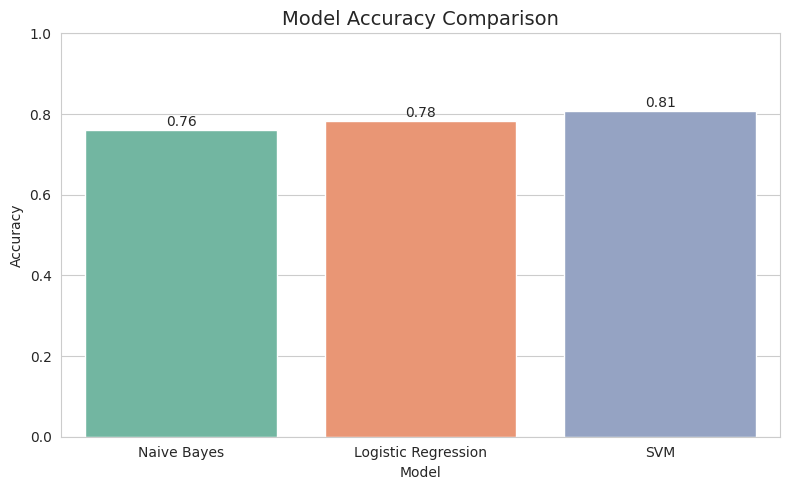

In [21]:
sns.set_style("whitegrid")
plt.figure(figsize=(8,5))

df_accuracy = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm)
    ]
})

# Plot
sns.barplot(
    x="Model",
    y="Accuracy",
    hue="Model",
    data=df_accuracy,
    palette="Set2",
    legend=False
)

plt.ylim(0, 1)
plt.title("Model Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy")
plt.xlabel("Model")

# Add value labels
for index, row in df_accuracy.iterrows():
    plt.text(
        index,
        row["Accuracy"] + 0.01,
        f"{row['Accuracy']:.2f}",
        ha='center',
        fontsize=10
    )

plt.tight_layout()
plt.show()

# ***Precision, Recall, and F1-Score Comparison***

In [22]:
# Dataframe Creation with the Results

data = {
    'Model': ['Naive Bayes', 'Naive Bayes', 'Logistic Regression', 'Logistic Regression', 'SVM', 'SVM'],
    'Class': ['0','1','0','1','0','1'],
    'Precision': [0.80, 0.73, 0.76, 0.81, 0.79, 0.82],
    'Recall': [0.70, 0.82, 0.83, 0.73, 0.83, 0.78],
    'F1-score': [0.74, 0.77, 0.79, 0.77, 0.81, 0.80]
}

df_metrics = pd.DataFrame(data)

In [23]:
# Set Style

sns.set_style("whitegrid")
plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

In [24]:
# Melt the dataframe for seaborn
df_melted = df_metrics.melt(id_vars=['Model','Class'], value_vars=['Precision','Recall','F1-score'],
                            var_name='Metric', value_name='Score')

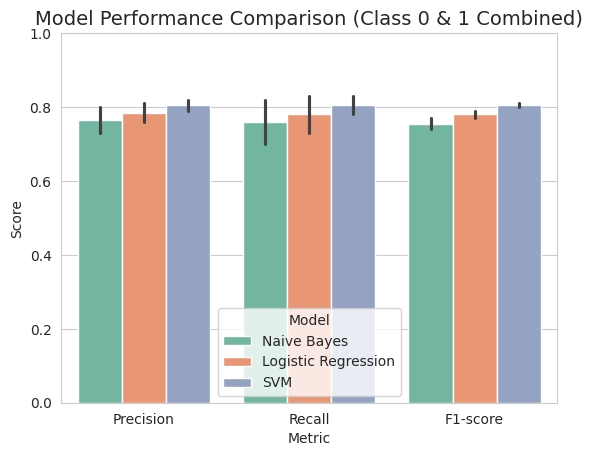

In [25]:
# Plot grouped bar chart
sns.barplot(x='Metric', y='Score', hue='Model', data=df_melted, palette='Set2')
plt.ylim(0,1)
plt.title("Model Performance Comparison (Class 0 & 1 Combined)", fontsize=14)
plt.ylabel("Score")
plt.xlabel("Metric")
plt.legend(title='Model')
plt.show()

# ***Naive Bayes Feature Importance***

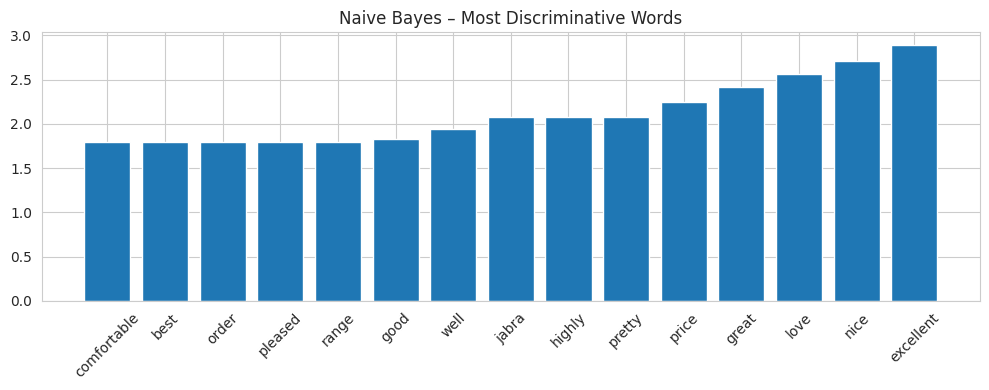

In [26]:
top_words_nb = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top_idx = np.argsort(top_words_nb)[-15:]

plt.figure(figsize=(10,4))
plt.bar(feature_names[top_idx], top_words_nb[top_idx])
plt.xticks(rotation=45)
plt.title("Naive Bayes – Most Discriminative Words")
plt.tight_layout()
plt.show()

# ***SVM Feature Importance***

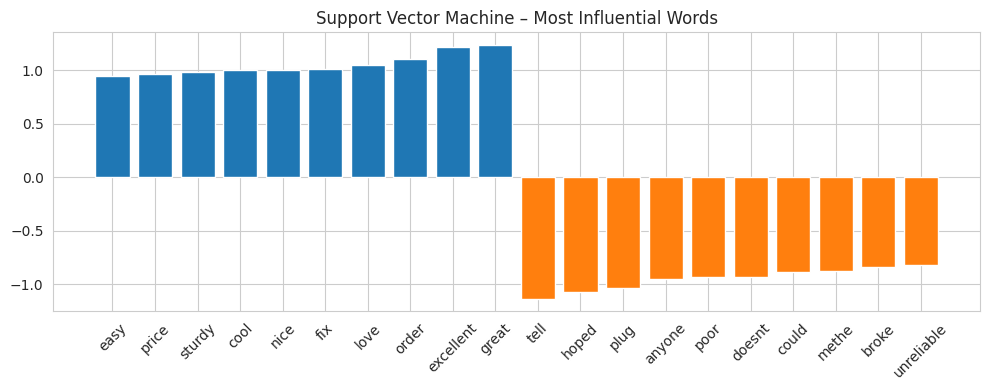

In [27]:
feature_names = vectorizer.get_feature_names_out()
coef = svm.coef_[0]

top_pos = np.argsort(coef)[-10:]
top_neg = np.argsort(coef)[:10]

plt.figure(figsize=(10,4))
plt.bar(feature_names[top_pos], coef[top_pos])
plt.bar(feature_names[top_neg], coef[top_neg])
plt.xticks(rotation=45)
plt.title("Support Vector Machine – Most Influential Words")
plt.tight_layout()
plt.show()

# ***Logistic Regression Feature Importance***

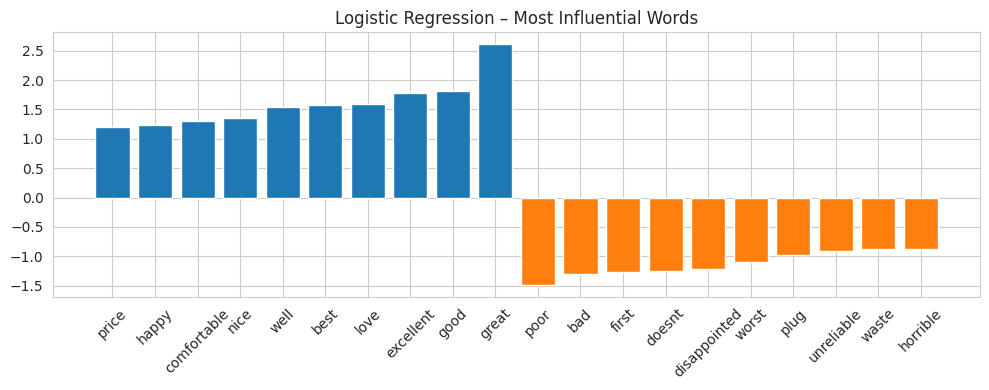

In [28]:
feature_names = vectorizer.get_feature_names_out()
coef = lr.coef_[0]

top_pos = np.argsort(coef)[-10:]
top_neg = np.argsort(coef)[:10]

plt.figure(figsize=(10,4))
plt.bar(feature_names[top_pos], coef[top_pos])
plt.bar(feature_names[top_neg], coef[top_neg])
plt.xticks(rotation=45)
plt.title("Logistic Regression – Most Influential Words")
plt.tight_layout()
plt.show()

# ***Task 3: BERT***

In [29]:
import numpy as np
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import torch
from torch.utils.data import Dataset
import torch.nn.functional as F

2026-01-20 10:48:46.268551: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1768906126.604228      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1768906126.695773      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1768906127.511767      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768906127.511816      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768906127.511819      55 computation_placer.cc:177] computation placer alr

In [30]:
# Dataset Class

class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

In [31]:
# Dataset Preparation

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["Cleaned_Sentence"].tolist(),
    df["Label"].tolist(),
    test_size=0.3,
    random_state=42,
    stratify=df["Label"]
)

train_dataset = ReviewDataset(X_train_text, y_train, tokenizer)
test_dataset = ReviewDataset(X_test_text, y_test, tokenizer)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

In [32]:
# Training BERT

model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=2
)

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=4,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    logging_steps=10,
    learning_rate=2e-5,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    tokenizer=tokenizer
)

trainer.train()

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipykernel_55/899571485.py:18: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Step,Training Loss
10,0.694000
20,0.703400
30,0.700500
40,0.613000
50,0.602400
60,0.496700
70,0.380900
80,0.392900
90,0.342900
100,0.606900


TrainOutput(global_step=700, training_loss=0.3238270895928144, metrics={'train_runtime': 50.9846, 'train_samples_per_second': 54.919, 'train_steps_per_second': 13.73, 'total_flos': 184177738752000.0, 'train_loss': 0.3238270895928144, 'epoch': 4.0})

In [33]:
# Model Evaluation

predictions = trainer.predict(test_dataset)
y_pred_bert = np.argmax(predictions.predictions, axis=1)

print("BERT Accuracy:", accuracy_score(y_test, y_pred_bert))
print(classification_report(y_test, y_pred_bert))

BERT Accuracy: 0.88
              precision    recall  f1-score   support

           0       0.86      0.91      0.88       150
           1       0.90      0.85      0.88       150

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300



# ***Confusion Matrix***

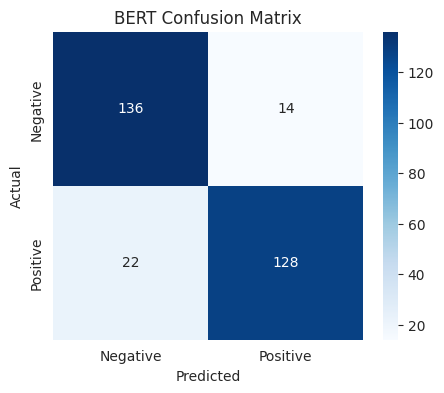

In [34]:
# Compute confusion matrix

cm = confusion_matrix(y_test, y_pred_bert)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Negative","Positive"], yticklabels=["Negative","Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BERT Confusion Matrix")
plt.show()

# ***Positive Probability per Review***

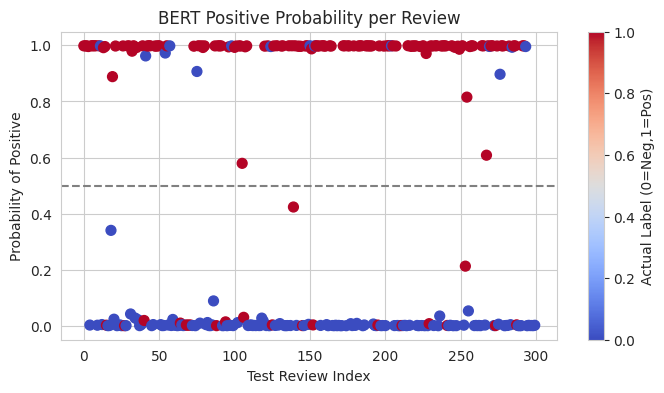

In [35]:
# Convert logits to probabilities
probs = F.softmax(torch.tensor(predictions.predictions), dim=1).numpy()

plt.figure(figsize=(8,4))
plt.scatter(range(len(probs)), probs[:,1], c=y_test, cmap='coolwarm', s=50)
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel("Test Review Index")
plt.ylabel("Probability of Positive")
plt.title("BERT Positive Probability per Review")
plt.colorbar(label="Actual Label (0=Neg,1=Pos)")
plt.show()

# ***ROC-AUC of BERT***

In [36]:
from sklearn.metrics import roc_curve, auc

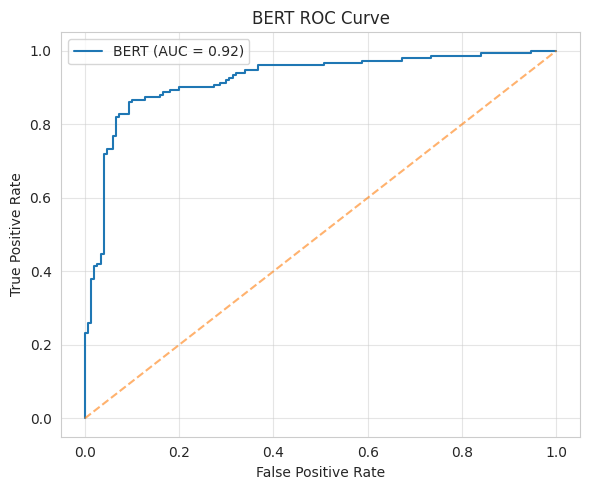

In [37]:
y_true = np.array(y_test)
y_score = probs[:, 1]

fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'BERT (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], linestyle='--', alpha=0.6)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('BERT ROC Curve')
plt.legend()
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

# ***Confidence Distribution***

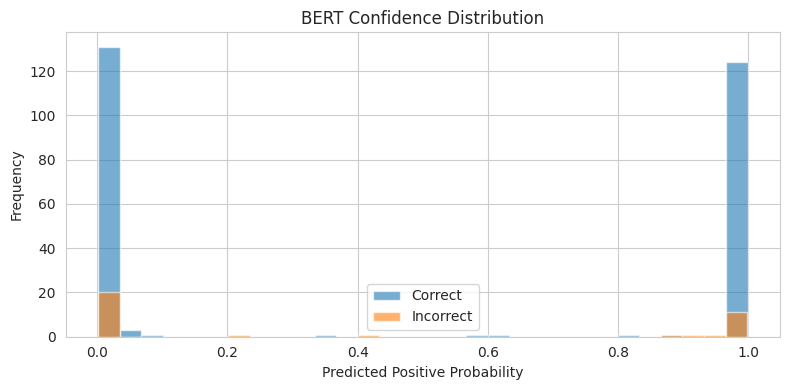

In [38]:
correct = y_pred_bert == y_true

plt.figure(figsize=(8,4))
plt.hist(probs[correct, 1], bins=30, alpha=0.6, label="Correct")
plt.hist(probs[~correct, 1], bins=30, alpha=0.6, label="Incorrect")
plt.xlabel("Predicted Positive Probability")
plt.ylabel("Frequency")
plt.title("BERT Confidence Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# ***Calibration Curver***

In [39]:
from sklearn.calibration import calibration_curve

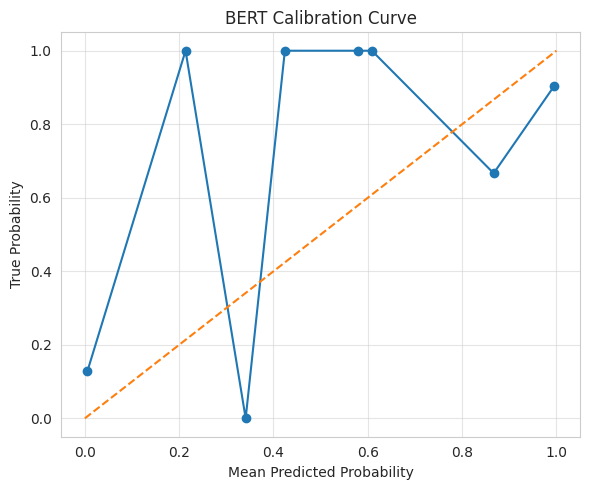

In [40]:
prob_true, prob_pred = calibration_curve(y_true, y_score, n_bins=10)

plt.figure(figsize=(6,5))
plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("Mean Predicted Probability")
plt.ylabel("True Probability")
plt.title("BERT Calibration Curve")
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

# ***Task 4: Topic Modelling***

In [41]:
from sklearn.decomposition import LatentDirichletAllocation

In [42]:
lda = LatentDirichletAllocation(
    n_components=10,
    random_state=42,
    learning_method='batch'
)

lda.fit(X_bow)

LatentDirichletAllocation(random_state=42)

In [43]:
feature_names = vectorizer.get_feature_names_out()

def display_topics(model, feature_names, num_words=6):
    for idx, topic in enumerate(model.components_):
        print(f"\nTopic {idx+1}:")
        print(", ".join([feature_names[i] for i in topic.argsort()[:-num_words - 1:-1]]))

display_topics(lda, feature_names)


Topic 1:
recommend, would, headset, good, great, bluetooth

Topic 2:
poor, phone, quality, good, get, audio

Topic 3:
work, im, product, headset, happy, good

Topic 4:
product, good, excellent, great, phone, price

Topic 5:
battery, life, good, phone, one, bad

Topic 6:
great, service, phone, work, customer, year

Topic 7:
phone, ever, best, item, worst, use

Topic 8:
phone, use, like, easy, battery, problem

Topic 9:
dont, phone, waste, sound, money, one

Topic 10:
phone, love, thing, one, headset, could


# ***Topic-Word Importance***

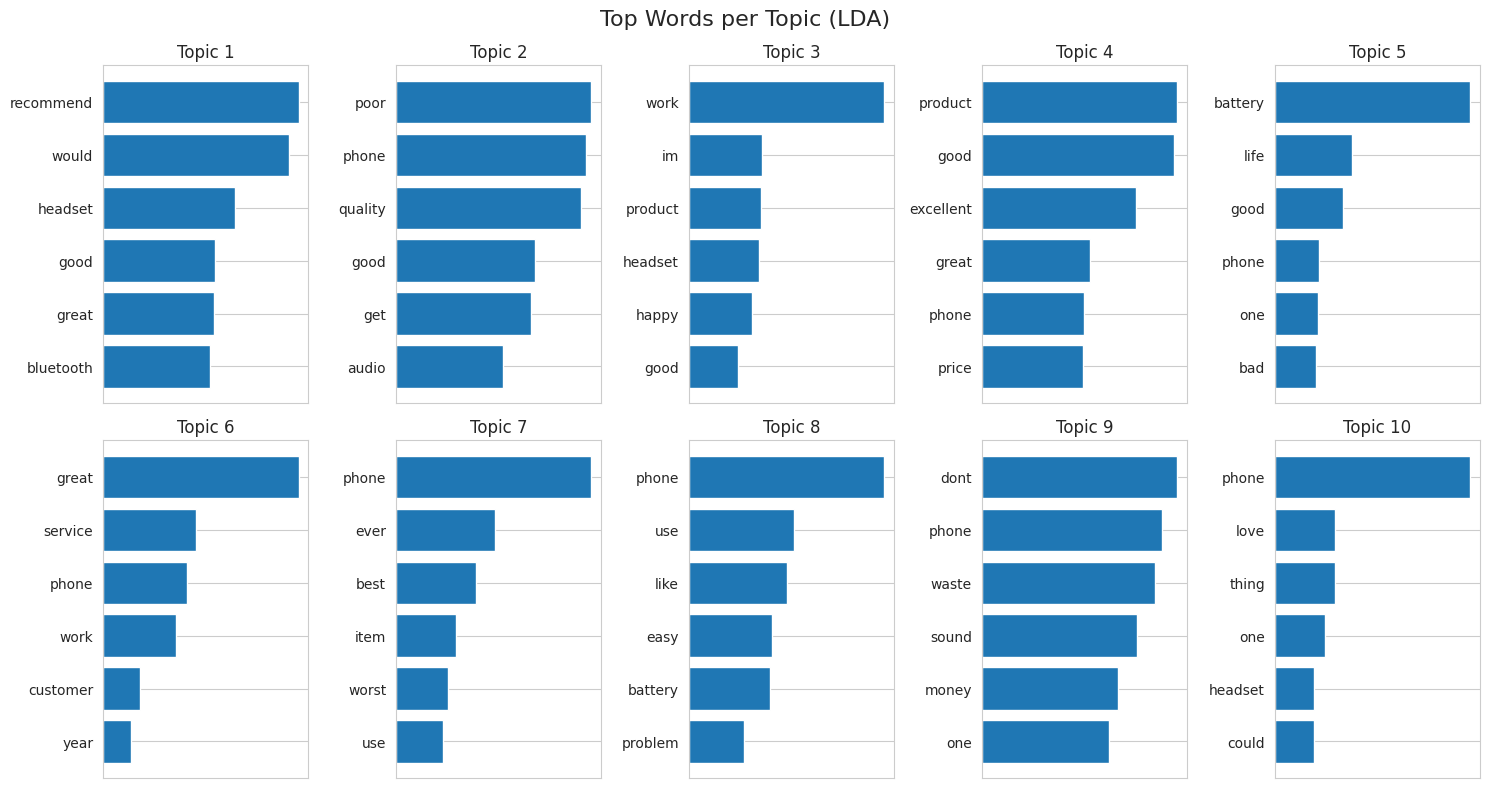

In [44]:
def plot_top_words(model, feature_names, n_top_words=6):
    n_topics = model.n_components
    plt.figure(figsize=(15, 8))

    for topic_idx, topic in enumerate(model.components_):
        top_features_idx = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_idx]
        weights = topic[top_features_idx]

        plt.subplot(2, 5, topic_idx + 1)
        plt.barh(top_features, weights)
        plt.title(f"Topic {topic_idx + 1}")
        plt.gca().invert_yaxis()
        plt.xticks([])

    plt.suptitle("Top Words per Topic (LDA)", fontsize=16)
    plt.tight_layout()
    plt.show()

plot_top_words(lda, feature_names)

# ***Dominant Topic Distribution***

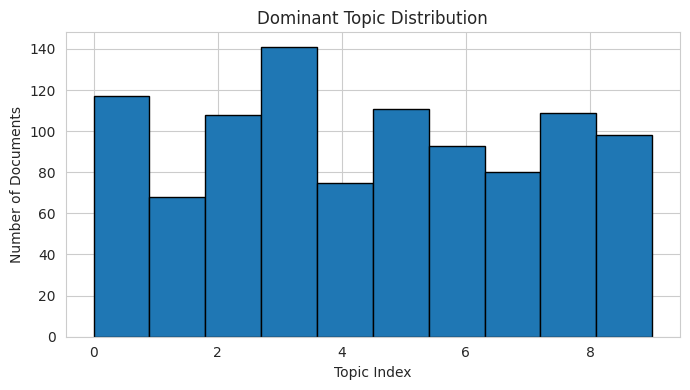

In [45]:
doc_topic_dist = lda.transform(X_bow)
dominant_topics = np.argmax(doc_topic_dist, axis=1)

plt.figure(figsize=(7,4))
plt.hist(dominant_topics, bins=10, edgecolor='black')
plt.xlabel("Topic Index")
plt.ylabel("Number of Documents")
plt.title("Dominant Topic Distribution")
plt.tight_layout()
plt.show()

## LDA Topic Modeling Analysis

Latent Dirichlet Allocation (LDA) was used to discover **10 hidden topics** in the reviews using Bag-of-Words features. Each topic is represented by its **top words**.

---

### Topics and Interpretation

| Topic | Top Words | Interpretation |
|-------|-----------|----------------|
| 1 | recommend, would, headset, good, great, bluetooth | Positive recommendations for headsets |
| 2 | poor, phone, quality, good, get, audio | Complaints about phone/audio quality |
| 3 | work, im, product, headset, happy, good | Users satisfied with products working as expected |
| 4 | product, good, excellent, great, phone, price | Positive reviews highlighting quality and value |
| 5 | battery, life, good, phone, one, bad | Discussions about battery life (positive and negative) |
| 6 | great, service, phone, work, customer, year | Experiences with customer service |
| 7 | phone, ever, best, item, worst, use | Extreme opinions (best/worst experiences) |
| 8 | phone, use, like, easy, battery, problem | General usability and issues with phone |
| 9 | dont, phone, waste, sound, money, one | Negative experiences, warnings (“don’t buy”) |
| 10 | phone, love, thing, one, headset, could | Positive sentiment, users expressing enjoyment |

---

### Key Insights

- **Positive vs Negative Themes:**  
  Topics 1, 3, 4, 10 are mostly positive; Topics 2, 5, 9 highlight negative experiences.  

- **Feature Focus:**  
  Words like `headset`, `phone`, `battery`, `sound`, and `service` appear frequently, indicating important product features.  

- **Customer Sentiment Detection:**  
  LDA separates reviews into positive and negative themes **without labeled data**.  

- **Actionable Insights:**  
  - Strengths: headset quality, battery life, good service.  
  - Improvements needed: audio quality, phone problems, customer warnings.

---

### Critical Evaluation

**Advantages:**

- Unsupervised; no labels needed.  
- Helps summarize large text datasets.  
- Reveals hidden topics and recurring themes.

**Limitations:**

- Bag-of-Words ignores word order and context.  
- Overlapping words appear across multiple topics.  
- Choosing the number of topics (`n_components`) is subjective.  
- Short reviews may result in noisy topics.